<a href="https://colab.research.google.com/github/bforoura/ML26/blob/main/Module6_Ensemble_RF/wine_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to Ensemble Learning and Random Forests**


* This notebook explores the principles and practical applications of **Ensemble Learning** and **Random Forests** within machine learning.

* Individual classification models often suffer from **high variance, high bias**, or sensitivity to specific regions of feature space.

* **Ensemble methods** address these limitations by **aggregating** the predictions of multiple individual models referred to as **base estimators or weak learners** to achieve superior generalization performance and robustness compared to any single predictor.

* The main objective here is to implement, evaluate, and compare various ensemble techniques using a structured, real-world tabular dataset.

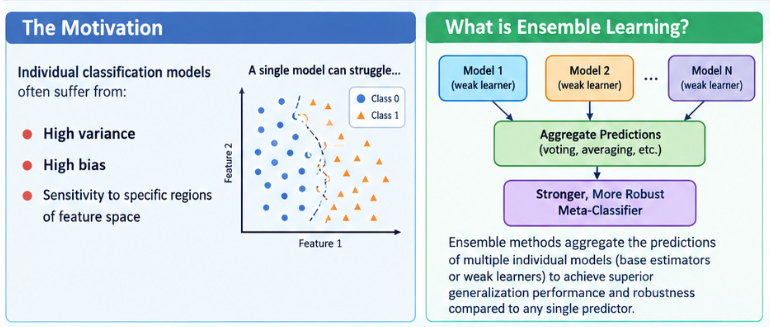


# **Topics Covered**

* **Voting Classifiers**:
   * Combining fundamentally different classification algorithms (Logistic Regression, Support Vector Machines, and Decision Trees) using both **Hard Voting** (majority rule) and **Soft Voting** (weighted probability aggregation) to create a stronger **meta-classifier**.


* **Bagging (Bootstrap Aggregating)**:
  * Training large base classifiers (**Decision Trees**) in parallel on random subsets of the training set drawn with replacement, thereby reducing prediction variance.

* **Out-of-Bag (OOB) Evaluation**:
  * Measuring generalization error implicitly using the subset of training instances left out during each bootstrap sample without requiring a separate validation set.

* **Random Forests**:
  * Scaling bagging specifically for Decision Trees while introducing random subspace feature selection at each node split to maximize tree diversity.

* **Boosting (AdaBoost)**:
  * Sequentially training weak learners (**decision stumps**) where each subsequent model focuses heavily on correcting the classification errors and misweighted instances of its predecessor.

  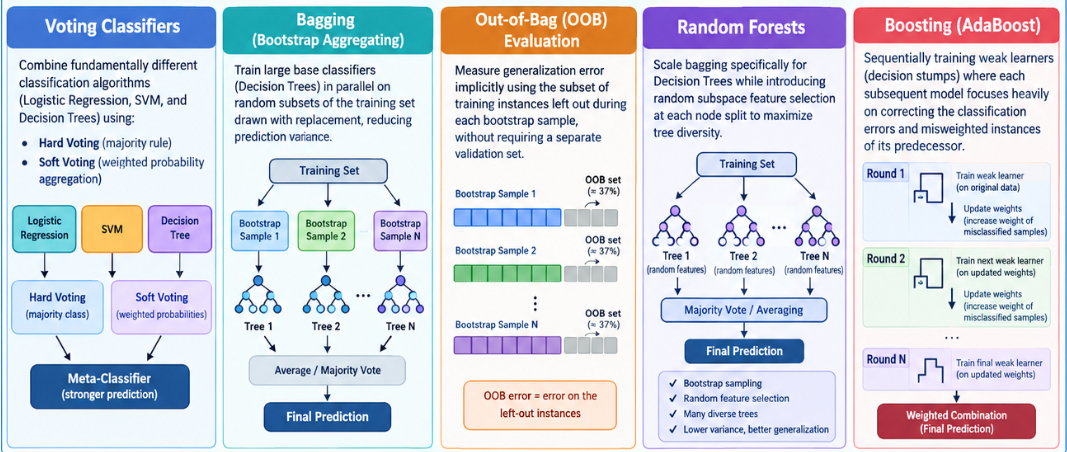

# **The Wine Recognition Dataset**

* To explore ensemble learning and random forest techniques, we use the standard** Wine dataset built into Scikit-Learn**.

* This dataset represents the chemical analysis of wines grown in the same region in Italy but derived from three different cultivars.

* The goal here is to perform **multi-class classification**.

* The dataset has **178 samples** with:
  * 13 continuous numerical attributes representing chemical components such as alcohol, malic acid, ash, alkalinity of ash, magnesium, total phenols, flavanoids, nonflavanoid phenols, proanthocyanins, color intensity, hue, etc.

  * Three distinct wine cultivars (**Class 0, Class 1, and Class 2**).

  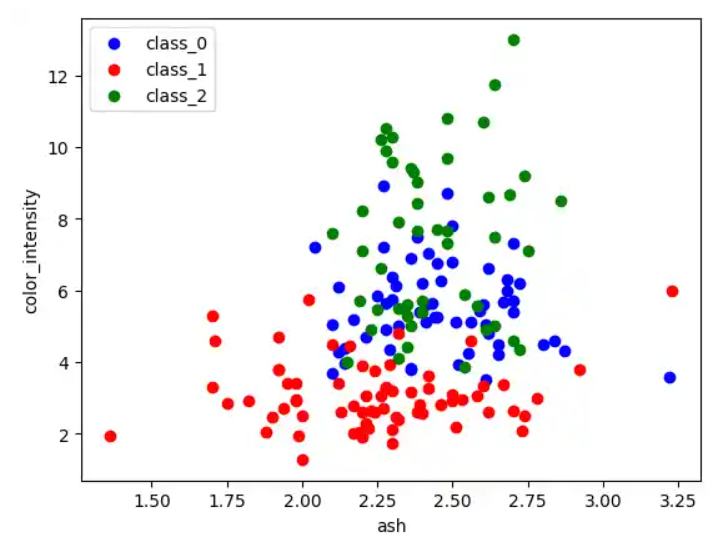

In [ ]:
from sklearn.datasets import load_wine
import pandas as pd

# Load the wine dataset as a pandas DataFrame for ease of analysis
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

# Display basic dataset dimensions and class distribution
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())

# Display the first few rows of the feature matrix
display(X.head())

Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


# **Voting Classifiers**


 * A **Voting Classifier** is an ensemble estimator that combines models representing different classification algorithms.

 * Rather than relying on a single predictor, it **aggregates** the predictions of **multiple individual models** to construct a **stronger meta-classifier** that balances out individual weaknesses on a dataset.   

 * Voting classifiers generally operate via two strategies:
   * **Hard Voting**:
      * Takes the **majority vote (statistical mode)** of the predicted class labels across all individual classifiers.   
   
   * **Soft Voting**:
      * Averages the predicted class probabilities from each classifier (provided they are well-calibrated)
      * Assigns the class label with the highest aggregated probability sum.
      
* **Soft voting typically yields superior performance** because it gives **more weight to confident predictions**.  

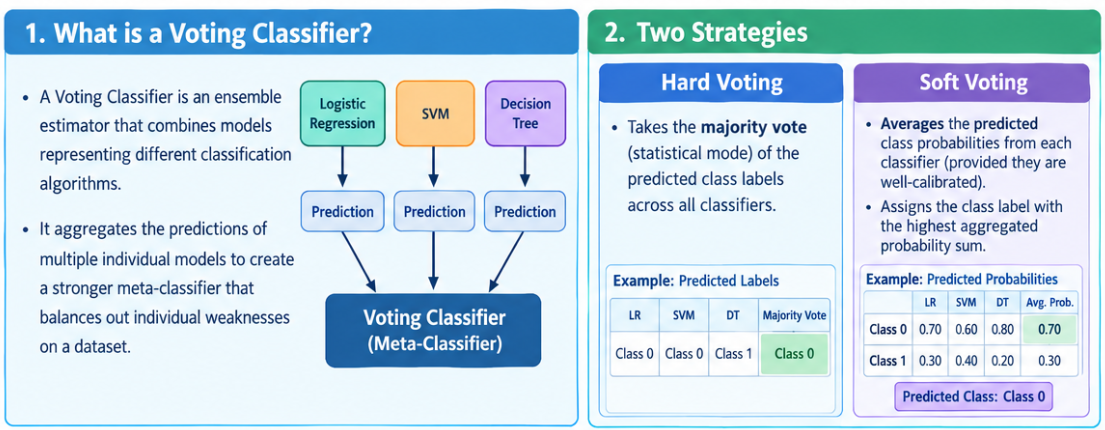

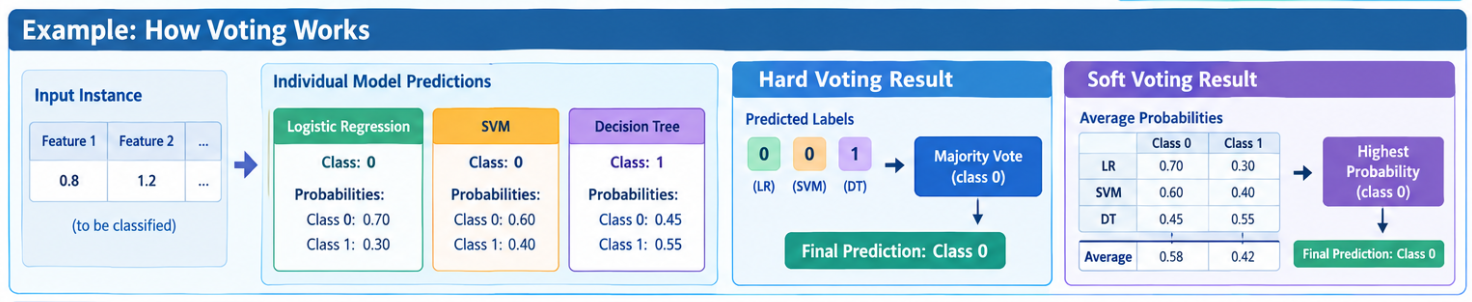

In [ ]:
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load the dataset
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Standardize features for optimal performance across all estimators
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize distinct classification models
log_clf = LogisticRegression(random_state=42, max_iter=5000)
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)

# Create a soft voting classifier combining the three estimators
voting_clf_soft = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("svc", svm_clf)],
    voting="soft",
)

# Train and evaluate individual classifiers and the voting ensemble on scaled data
print("Evaluating individual models and the voting ensemble with scaling:")
models = {
    "Logistic Regression": log_clf,
    "Random Forest": rnd_clf,
    "SVM": svm_clf,
    "Soft Voting": voting_clf_soft,
}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    print(f"{name:<25} Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Evaluating individual models and the voting ensemble with scaling:
Logistic Regression       Accuracy: 0.9778
Random Forest             Accuracy: 1.0000
SVM                       Accuracy: 0.9778
Soft Voting               Accuracy: 1.0000


# **Visualizing Model Performance**

* To clearly interpret and compare the performance of individual classifiers against the soft voting ensemble, we visualize their accuracy scores using a bar plot.

* This makes it straightforward to observe how combining multiple heterogeneous models improves generalization compared to any single classifier.

Logistic Regression       Accuracy: 0.9778
Random Forest             Accuracy: 1.0000
SVM                       Accuracy: 0.9778
Soft Voting               Accuracy: 1.0000


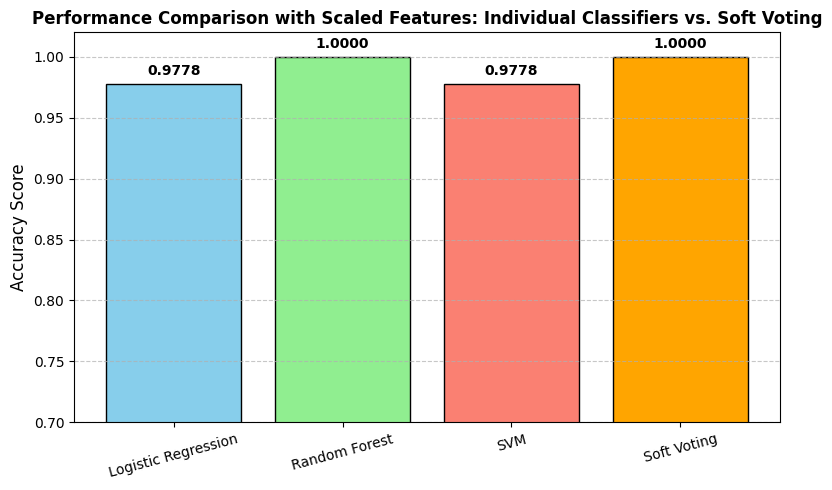

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load dataset and split into training and testing sets
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42
)

# Standardize features for distance-based estimators like SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
log_clf = LogisticRegression(random_state=42, max_iter=5000)
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)
voting_clf_soft = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("svc", svm_clf)],
    voting="soft",
)

models = {
    "Logistic Regression": log_clf,
    "Random Forest": rnd_clf,
    "SVM": svm_clf,
    "Soft Voting": voting_clf_soft,
}

names = []
accuracies = []

# Train and evaluate each model on scaled data
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    names.append(name)
    accuracies.append(acc)
    print(f"{name:<25} Accuracy: {acc:.4f}")

# Create the bar plot
plt.figure(figsize=(8, 5))
bars = plt.bar(
    names,
    accuracies,
    color=["skyblue", "lightgreen", "salmon", "orange"],
    edgecolor="black",
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "Performance Comparison with Scaled Features: Individual Classifiers vs. Soft Voting",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.70, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.xticks(rotation=15, fontsize=10)
plt.tight_layout()
plt.show()

# **Cross-Validation for Robust Performance Estimation**

* As we observed with smaller dataset splits, single test set evaluations can be heavily influenced by how data happens to be partitioned.

* Because the Wine dataset contains only 178 total instances, a single misclassified sample shifts the resulting accuracy score by over two percentage points.

* To obtain a reliable, statistically sound measure of generalization performance, we use **Stratified K-Fold Cross-Validation**.

* This technique divides the dataset into $K$ equal folds while **ensuring that each fold maintains the exact same proportion of target classes** as the complete dataset.

* Every model is trained $K$ times, using $K-1$ folds for training and the remaining fold for testing, ensuring that every sample is tested exactly once.
* The resulting scores are then averaged to eliminate partition bias.

In [ ]:
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load dataset
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target

# Initialize models
log_clf = LogisticRegression(random_state=42, max_iter=5000)
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)
voting_clf_soft = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("svc", svm_clf)],
    voting="soft",
)

# Use pipelines to ensure scaling is applied inside each cross-validation fold preventing data leakage
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), log_clf),
    "Random Forest": rnd_clf,  # Trees do not require scaling
    "SVM": make_pipeline(StandardScaler(), svm_clf),
    "Soft Voting (Pipeline)": VotingClassifier(
        estimators=[
            ("lr", make_pipeline(StandardScaler(), log_clf)),
            ("rf", rnd_clf),
            ("svc", make_pipeline(StandardScaler(), svm_clf)),
        ],
        voting="soft",
    ),
}

# Perform 5-fold stratified cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("5-Fold Stratified Cross-Validation Accuracy Scores:\n")
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    print(
        f"{name:<25} Mean Accuracy: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})"
    )

5-Fold Stratified Cross-Validation Accuracy Scores:

Logistic Regression       Mean Accuracy: 0.9833 (+/- 0.0272)
Random Forest             Mean Accuracy: 0.9775 (+/- 0.0426)
SVM                       Mean Accuracy: 0.9833 (+/- 0.0444)
Soft Voting (Pipeline)    Mean Accuracy: 0.9889 (+/- 0.0272)


5-Fold Stratified Cross-Validation Summary:

Logistic Regression       Mean Accuracy: 0.9833 (+/- 0.0272)
Random Forest             Mean Accuracy: 0.9775 (+/- 0.0426)
SVM                       Mean Accuracy: 0.9833 (+/- 0.0444)
Soft Voting               Mean Accuracy: 0.9889 (+/- 0.0272)


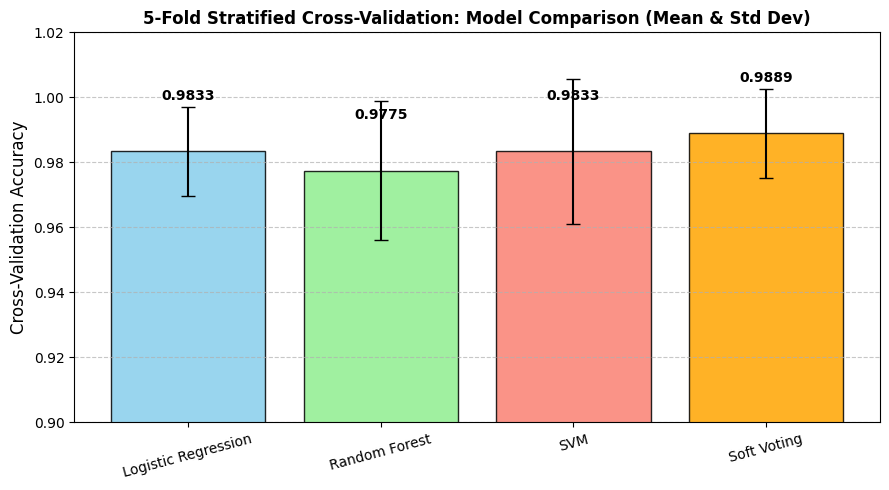

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load dataset
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target

# Initialize models
log_clf = LogisticRegression(random_state=42, max_iter=5000)
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), log_clf),
    "Random Forest": rnd_clf,
    "SVM": make_pipeline(StandardScaler(), svm_clf),
    "Soft Voting": VotingClassifier(
        estimators=[
            ("lr", make_pipeline(StandardScaler(), log_clf)),
            ("rf", rnd_clf),
            ("svc", make_pipeline(StandardScaler(), svm_clf)),
        ],
        voting="soft",
    ),
}

# Perform 5-fold stratified cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

names = []
means = []
stds = []

print("5-Fold Stratified Cross-Validation Summary:\n")
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    mean_acc = scores.mean()
    std_acc = scores.std()
    names.append(name)
    means.append(mean_acc)
    stds.append(std_acc)
    print(f"{name:<25} Mean Accuracy: {mean_acc:.4f} (+/- {std_acc * 2:.4f})")

# Create the bar plot with error bars
plt.figure(figsize=(9, 5))
bars = plt.bar(
    names,
    means,
    yerr=stds,
    capsize=5,
    color=["skyblue", "lightgreen", "salmon", "orange"],
    edgecolor="black",
    alpha=0.85,
)

plt.ylabel("Cross-Validation Accuracy", fontsize=12)
plt.title(
    "5-Fold Stratified Cross-Validation: Model Comparison (Mean & Std Dev)",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.90, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate mean accuracy values on top of each bar
for bar, mean_val in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        mean_val + 0.015,
        f"{mean_val:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.xticks(rotation=15, fontsize=10)
plt.tight_layout()
plt.show()

# **Individual Models Comparison**

 * **Logistic Regression** and **SVM** both achieved a strong mean accuracy of $0.9833$. However, SVM exhibited a slightly higher variance, reflecting greater sensitivity to particular fold distributions even with feature scaling.
 * **Random Forest** achieved a mean accuracy of $0.9775$, which is competitive and robust, though slightly lower than the top linear and kernel models on this specific tabular dataset.

 * The **Soft Voting pipeline** achieved the highest mean accuracy with a low variance. This demonstrates the core principle of ensemble learning that combining diverse models **balances out individual weaknesses and constructs a stronger meta-classifier**.

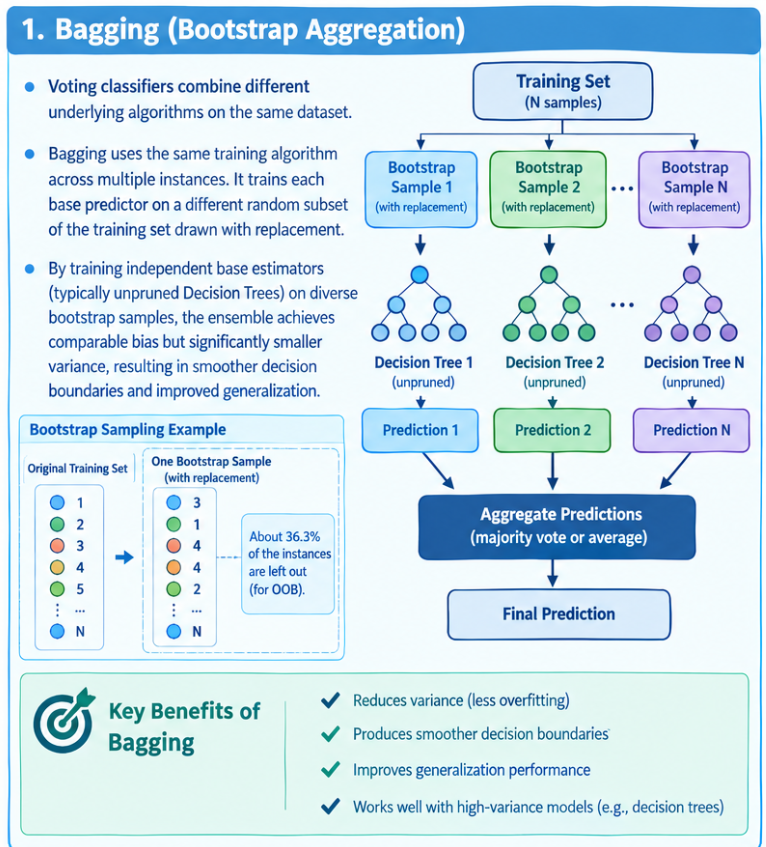

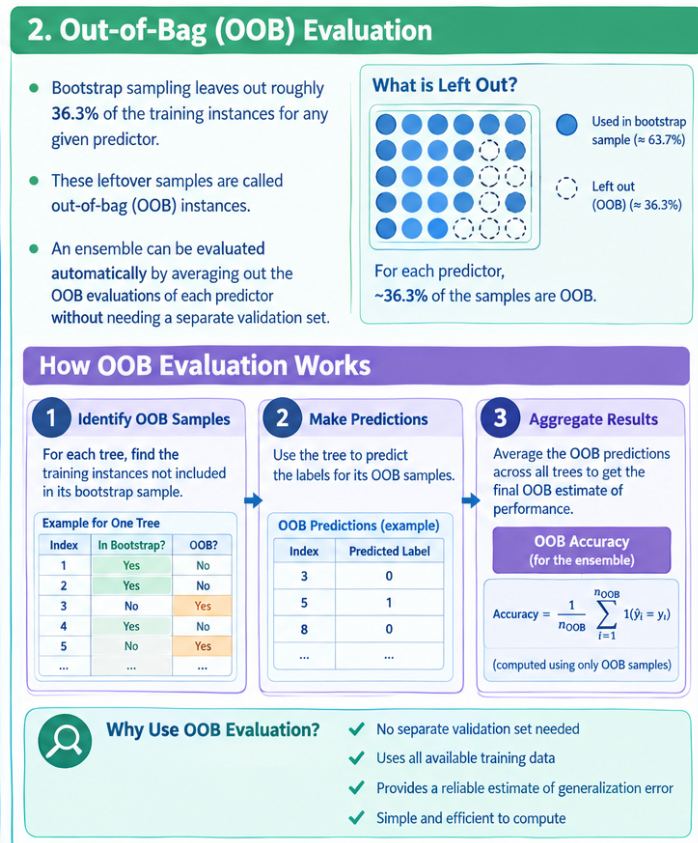

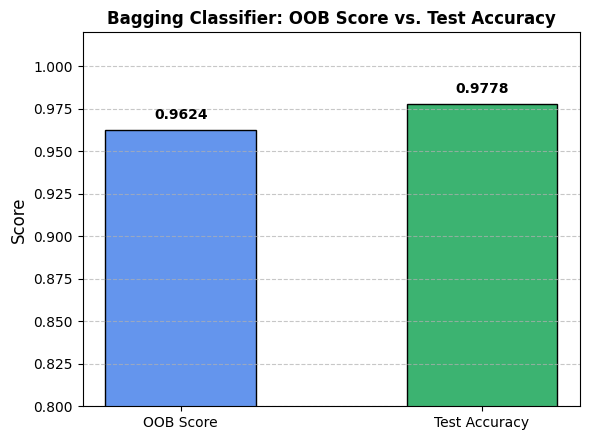

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Load dataset and split into training and testing sets
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42
)

# Initialize a Bagging Classifier using Decision Trees with OOB evaluation enabled
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=500,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
)

# Fit the bagging classifier on the training data
bag_clf.fit(X_train, y_train)

# Evaluate on the test set
y_pred = bag_clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

# Prepare data for plotting
metrics = ["OOB Score", "Test Accuracy"]
scores = [bag_clf.oob_score_, test_accuracy]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["cornflowerblue", "mediumseagreen"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Score", fontsize=12)
plt.title(
    "Bagging Classifier: OOB Score vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.80, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

# **Explanation of Bagging Results**

 * **Out-of-Bag (OOB) Score (0.9624)**
   * The OOB score measures how well the ensemble's individual decision trees generalize to training instances they were not exposed to during bootstrap sampling.
   
   * An OOB score of $0.9624$ confirms that the bagging ensemble performs strongly even on unseen training partitions, serving as an efficient built-in validation mechanism without requiring a separate cross-validation split.   
   
 * **Test Accuracy (0.9778)**
    * The test accuracy evaluated on the held-out test split is $0.9778$.
    
    * This indicates that roughly 44 out of 45 test samples were classified correctly.
    
    *  The slightly higher test accuracy compared to the OOB score is common in smaller datasets due to the random variation inherent in specific test set distributions.

# **Random Forests**

 * A **Random Forest** is an **ensemble of decision trees generally trained via bagging (bootstrap aggregating), where each tree is built using a random subset of the training data**.

 * However, Random Forests introduce an additional layer of randomness: rather than searching for the absolute best feature when splitting a node, each tree is restricted to searching across a **random subset of features** (controlled by max_features).   

 * This injected diversity decorrelates the individual trees, preventing dominant features from dictating every split.

 * As a result, the ensemble achieves lower prediction variance and superior generalization compared to standard bagging or individual decision trees.

 * Furthermore, Random Forests allow us to easily measure feature importance by tracking how much impurity is reduced across all trees in the forest for each feature.

 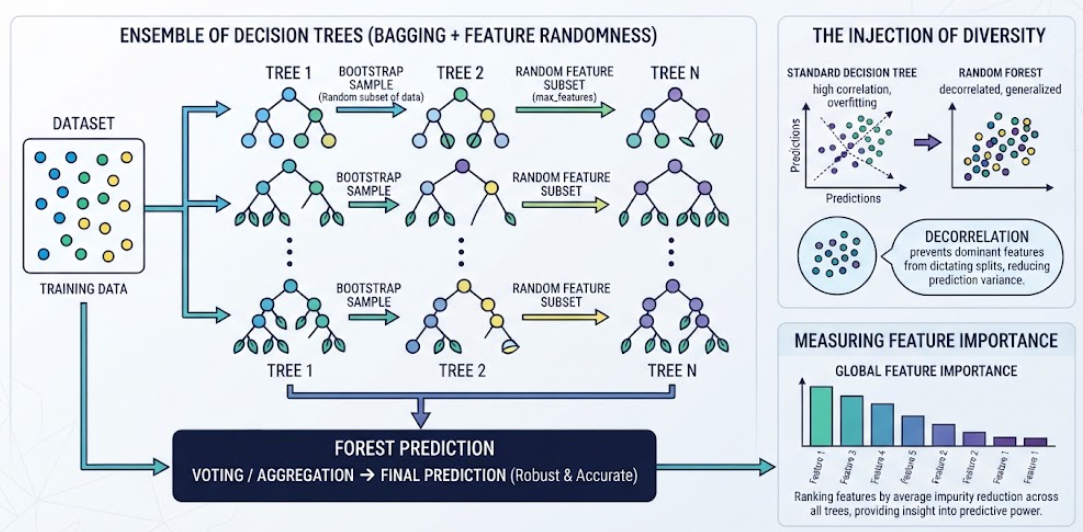

Random Forest Test Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



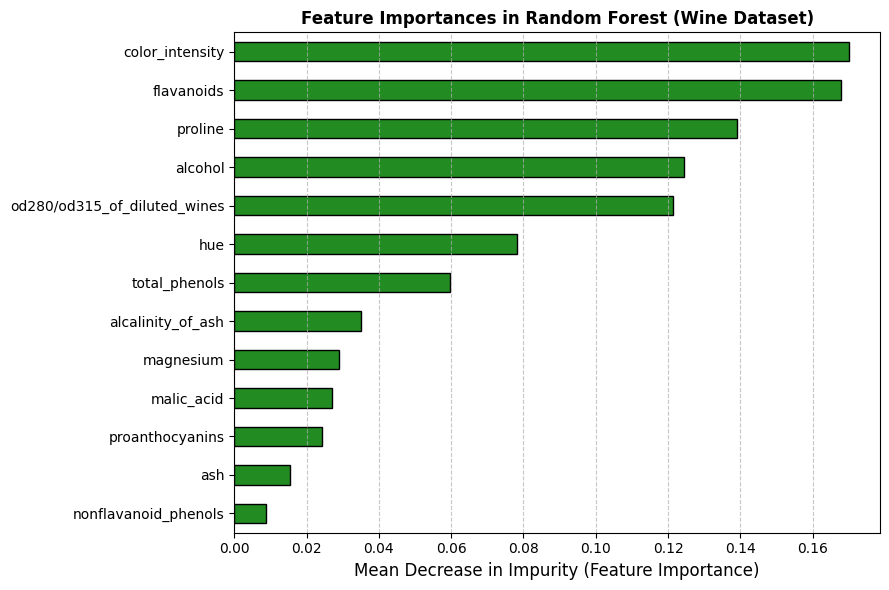

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# Load dataset and split into training and testing sets
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42
)

# Initialize the Random Forest Classifier
rf_clf = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", random_state=42, n_jobs=-1
)

# Train the model
rf_clf.fit(X_train, y_train)

# Evaluate on the test set
y_pred = rf_clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Random Forest Test Accuracy: {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

# Extract and display feature importances
importances = pd.Series(rf_clf.feature_importances_, index=wine.feature_names)
importances_sorted = importances.sort_values(ascending=True)

# Plot feature importances
plt.figure(figsize=(9, 6))
importances_sorted.plot(kind="barh", color="forestgreen", edgecolor="black")
plt.xlabel("Mean Decrease in Impurity (Feature Importance)", fontsize=12)
plt.title(
    "Feature Importances in Random Forest (Wine Dataset)",
    fontsize=12,
    fontweight="bold",
)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

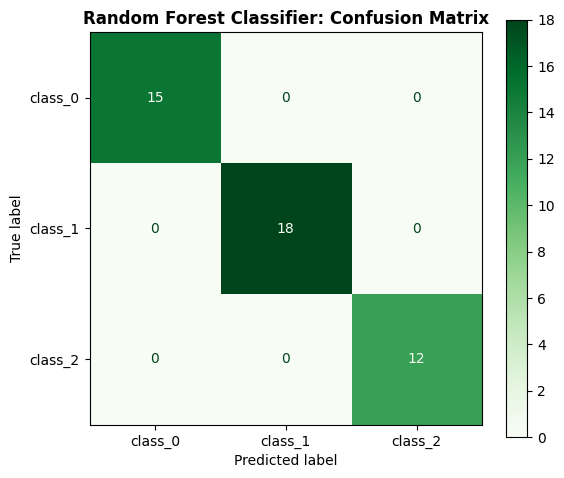

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

# Load dataset and split into training and testing sets
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42
)

# Initialize and train the Random Forest Classifier
rf_clf = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", random_state=42, n_jobs=-1
)
rf_clf.fit(X_train, y_train)

# Generate predictions on the test set
y_pred = rf_clf.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix as a heatmap
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=wine.target_names
)
disp.plot(cmap=plt.cm.Greens, values_format="d", ax=ax, colorbar=True)

plt.title(
    "Random Forest Classifier: Confusion Matrix", fontsize=12, fontweight="bold"
)
plt.grid(False)
plt.tight_layout()
plt.show()

# **Boosting (Adaptive Boosting / AdaBoost)**


* While **bagging** and **random forests** build independent predictors in parallel, **Boosting** refers to any ensemble method that can **combine several weak learners into a strong learner sequentially**.

* The general idea is to train predictors sequentially, where each subsequent model tries to correct the errors of its predecessor.

* **AdaBoost (Adaptive Boosting)** achieves this by paying more attention to training instances that were underfitted or misclassified by previous models:

  * Initially, all training instances are given equal weights.

  * After a base classifier is trained, its error rate on the weighted training set is evaluated, and **the classifier is assigned a weight based on its overall accuracy**.

  * The **weights of the misclassified instances are then increased, forcing the next consecutive classifier to focus more attention on the hard-to-classify examples.**

  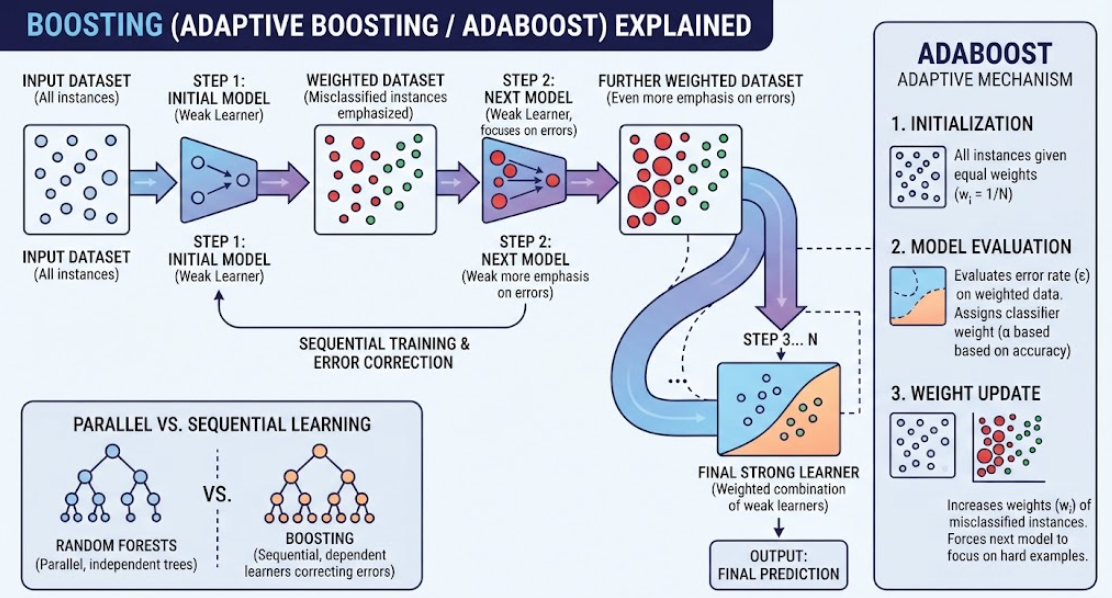

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


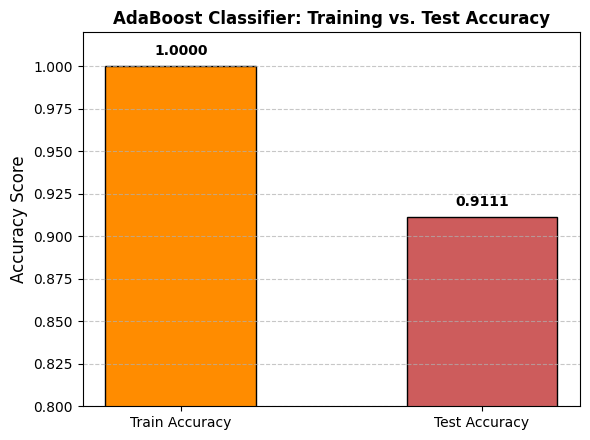

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Load dataset and split into training and testing sets
wine = load_wine(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, random_state=42
)

# Initialize the AdaBoost Classifier using Decision Stumps (max_depth=1)
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=200,
    algorithm="SAMME",
    learning_rate=0.5,
    random_state=42,
)

# Train the model
ada_clf.fit(X_train, y_train)

# Evaluate accuracies
train_accuracy = accuracy_score(y_train, ada_clf.predict(X_train))
test_accuracy = accuracy_score(y_test, ada_clf.predict(X_test))

# Prepare data for plotting
metrics = ["Train Accuracy", "Test Accuracy"]
scores = [train_accuracy, test_accuracy]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["darkorange", "indianred"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "AdaBoost Classifier: Training vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.80, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

# **Explanation of AdaBoost Results**


* The evaluation plot reveals a **significant performance gap** between the **training set** and the **test set**:

* **The AdaBoost classifier** achieved a perfect score on the training data. Because boosting trains models sequentially,  where each new decision stump focuses heavily on the instances misclassified by the previous estimator, the ensemble successfully adapted to fit every single training sample.

* On the held-out test set, the accuracy drops to approximately 91.11%. While this is still a reasonable score, it is noticeably lower than the results achieved by Random Forests, Bagging, or Voting Classifiers on this dataset.



# **Overfitting in Boosting**

  * The discrepancy between 100% training accuracy and 91.11% test accuracy is a classic indicator of **overfitting**.

  * Because **AdaBoost** targets difficult or noisy data points during sequential training, it can become **overly sensitive to patterns in the  training set**, reducing its ability to generalize cleanly to unseen data.
  * **Adjusting hyperparameters like learning rate** (learning_rate) or **reducing the number of estimators (n_estimators)** can help regularize the model and bridge this gap.

  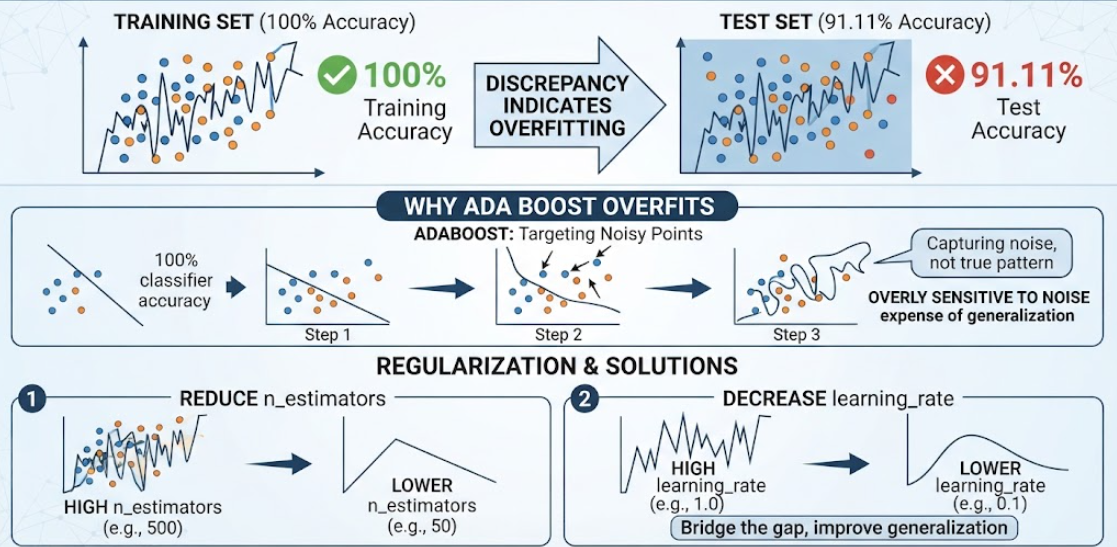